In [2]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns   


In [3]:
df= pd.read_csv('/Users/Admin/Documents/proyectosAnalisisDatos/Pandas/Data/sales_data_correlated.csv')


parts = df['Purchase Address'].astype(str).str.split(',', n=2, expand=True)
df['City'] = parts[1].str.strip()   # parts[1] es la columna 'City'

display(df.head())

,Order ID,Product,Price Each,Order Date,Purchase Address,Quantity Ordered,City
0,176633,Flatscreen TV,13.69,2023-01-01,"492 Main St, Phoenix, AZ",4,Phoenix
1,176592,Wired Headphones,13.28,2023-01-02,"910 Main St, Dallas, TX",4,Dallas
2,176655,Macbook Pro Laptop,14.27,2023-01-03,"345 Main St, Portland, OR",4,Portland
3,176586,Flatscreen TV,15.77,2023-01-04,"275 Main St, Los Angeles, CA",3,Los Angeles
4,176626,Google Phone,12.30,2023-01-05,"138 Main St, San Francisco, CA",4,San Francisco


In [5]:
# preparar nuestras columnas
X=df[['Price Each']] #variable independiente
Y= df[['Quantity Ordered']] #variable dependiente
 

Coeficientes de la regresión múltiple: [[-0.01065119]]
Intercepto de la regresión múltiple: [2.01304692]


C:\Users\Admin\AppData\Local\Temp\ipykernel_24096\337068224.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df,x='Price Each',y='Quantity Ordered',s=40, alpha=0.6, palette='Set2')


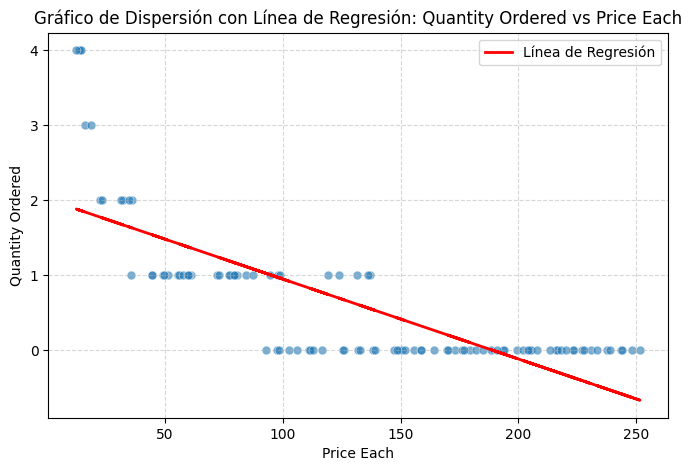

In [11]:
model = LinearRegression()
model.fit(X,Y)  #ajustar el modelo
y_pred = model.predict(X)  #predecir los valores de Y basados en X

print("Coeficientes de la regresión múltiple:", model.coef_)
print("Intercepto de la regresión múltiple:", model.intercept_)

#Graficar los resultados
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x='Price Each',y='Quantity Ordered',s=40, alpha=0.6, palette='Set2')
plt.plot(X, y_pred, color='red', linewidth=2, label='Línea de Regresión')
plt.title('Gráfico de Dispersión con Línea de Regresión: Quantity Ordered vs Price Each')
plt.xlabel('Price Each')
plt.ylabel('Quantity Ordered')  
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5 )
plt.show()

In [ ]:
#Evaluar el modelo
#Proporcion de la varianza explicada por el modelo
r_squared = model.score(X,Y)
print(f'R²: {r_squared:.4f}')

R²: 0.5846


In [8]:
df['Order Month'] = pd.to_datetime(df['Order Date']).dt.month
df.head()

,Order ID,Product,Price Each,Order Date,Purchase Address,Quantity Ordered,City,Order Month
0,176633,Flatscreen TV,13.69,2023-01-01,"492 Main St, Phoenix, AZ",4,Phoenix,1
1,176592,Wired Headphones,13.28,2023-01-02,"910 Main St, Dallas, TX",4,Dallas,1
2,176655,Macbook Pro Laptop,14.27,2023-01-03,"345 Main St, Portland, OR",4,Portland,1
3,176586,Flatscreen TV,15.77,2023-01-04,"275 Main St, Los Angeles, CA",3,Los Angeles,1
4,176626,Google Phone,12.30,2023-01-05,"138 Main St, San Francisco, CA",4,San Francisco,1


In [9]:
X_multiple =df[['Price Each','Order Month']]  #variables independientes
model_multiple = LinearRegression()
model_multiple.fit(X_multiple,Y)

print("Coeficientes de la regresión múltiple:", model_multiple.coef_)
print("Intercepto de la regresión múltiple:", model_multiple.intercept_)

Coeficientes de la regresión múltiple: [[-0.01734583  0.49836503]]
Intercepto de la regresión múltiple: [1.78593736]


In [10]:
r_squared_multiple = model_multiple.score(X_multiple,Y)
print(f'R² de la regresión múltiple: {r_squared_multiple:.4f}')

R² de la regresión múltiple: 0.6090


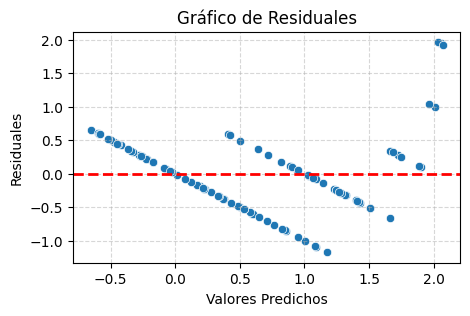

In [22]:
# Calcular los valores predichos
y_pred = model_multiple.predict(X_multiple)

# Aseguramos que Y y y_pred sean vectores 1D
y_pred = y_pred.flatten()          # o .ravel()
Y = np.array(Y).flatten()          # convierte Series o DataFrame en array 1D

# Calcular los residuales
residuales = Y - y_pred

# Gráfico de residuales
plt.figure(figsize=(5,3))
sns.scatterplot(x=y_pred, y=residuales)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.title('Gráfico de Residuales')
plt.xlabel('Valores Predichos')
plt.ylabel('Residuales')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
